Dependencies

In [ ]:
!pip install osmium pandas shapely folium

Extract a Small Sample of Mumbai Roads

In [3]:
import osmium
import pandas as pd
import math

class SmallAreaExtractor(osmium.SimpleHandler):
    def __init__(self, min_lat, max_lat, min_lon, max_lon):
        super().__init__()
        self.min_lat = min_lat
        self.max_lat = max_lat
        self.min_lon = min_lon
        self.max_lon = max_lon
        
        self.nodes = {}
        self.road_segments = []
        
        # Roads accessible by cars
        self.valid_highways = {
            'motorway', 'trunk', 'primary', 'secondary', 'tertiary',
            'motorway_link', 'trunk_link', 'primary_link', 'secondary_link',
            'residential', 'unclassified'
        }

    def node(self, n):
        # Store nodes inside our target bounding box
        if self.min_lat <= n.location.lat <= self.max_lat and self.min_lon <= n.location.lon <= self.max_lon:
            self.nodes[n.id] = (n.location.lat, n.location.lon)

    def way(self, w):
        hw = w.tags.get('highway')
        if hw in self.valid_highways:
            # Check how many nodes of this road fall in our target box
            valid_node_ids = [n.ref for n in w.nodes if n.ref in self.nodes]
            
            # If at least 2 nodes match, we have a drivable segment in our zone
            if len(valid_node_ids) >= 2:
                road_name = w.tags.get('name', 'Unnamed Road')
                oneway = w.tags.get('oneway') in ['yes', '1', 'true']
                
                for i in range(len(valid_node_ids) - 1):
                    u = valid_node_ids[i]
                    v = valid_node_ids[i+1]
                    lat1, lon1 = self.nodes[u]
                    lat2, lon2 = self.nodes[v]
                    
                    # Calculate segment length (Haversine formula in meters)
                    dlat = math.radians(lat2 - lat1)
                    dlon = math.radians(lon2 - lon1)
                    a = math.sin(dlat/2)**2 + math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) * math.sin(dlon/2)**2
                    dist_meters = 6371000 * 2 * math.atan2(math.sqrt(a), math.sqrt(1-a))
                    
                    # Calculate compass bearing (heading 0° to 360°)
                    y = math.sin(dlon) * math.cos(math.radians(lat2))
                    x = math.cos(math.radians(lat1)) * math.sin(math.radians(lat2)) - \
                        math.sin(math.radians(lat1)) * math.cos(math.radians(lat2)) * math.cos(dlon)
                    bearing = (math.degrees(math.atan2(y, x)) + 360.0) % 360.0

                    self.road_segments.append({
                        "road_name": road_name,
                        "highway_type": hw,
                        "from_node": u,
                        "to_node": v,
                        "from_lat": lat1,
                        "from_lon": lon1,
                        "to_lat": lat2,
                        "to_lon": lon2,
                        "length_m": round(dist_meters, 2),
                        "bearing_deg": round(bearing, 1),
                        "oneway": oneway
                    })

# Bounding box for BKC (Bandra-Kurla Complex), Mumbai
extractor = SmallAreaExtractor(
    min_lat=19.055, max_lat=19.075,
    min_lon=72.855, max_lon=72.885
)

print("Extracting sample road segments from BKC...")
extractor.apply_file("surveillance-app/western-zone-261028.osm.pbf", locations=True)

df_roads = pd.DataFrame(extractor.road_segments)
print(f"Extracted {len(df_roads)} road segments!")
df_roads.head(10)

Extracting sample road segments from BKC...
Extracted 4495 road segments!


,road_name,highway_type,from_node,to_node,from_lat,from_lon,to_lat,to_lon,length_m,bearing_deg,oneway
0,S G Barve Marg,tertiary,1366009000,2246472055,19.066824,72.877716,19.066119,72.878717,131.14,126.7,False
1,S G Barve Marg,tertiary,2246472055,1366008980,19.066119,72.878717,19.065860,72.879043,44.80,130.1,False
2,S G Barve Marg,tertiary,1366008980,1366008998,19.065860,72.879043,19.066552,72.879465,88.87,30.0,False
3,Avenue 5: Lane 3,tertiary,14211323818,245666078,19.062117,72.867847,19.062116,72.867965,12.38,90.8,True
4,Avenue 5: Lane 3,tertiary,245666078,13617211711,19.062116,72.867965,19.062140,72.868302,35.55,85.7,True
5,Avenue 5: Lane 3,tertiary,13617211711,2897024603,19.062140,72.868302,19.062180,72.868874,60.27,85.7,True
6,Street 5,tertiary,2897024651,2897024645,19.065213,72.862260,19.064982,72.862543,39.23,130.8,True
7,Street 5,tertiary,2897024645,13231848257,19.064982,72.862543,19.064971,72.862555,1.78,132.9,True
8,Street 5,tertiary,13231848257,6554384653,19.064971,72.862555,19.064652,72.862920,52.29,132.8,True
9,Street 5,tertiary,6554384653,13231848260,19.064652,72.862920,19.064633,72.862941,3.06,132.9,True


Visualizing the Extracted Sample

In [ ]:
import folium

# Center the map at BKC
m = folium.Map(location=[19.065, 72.870], zoom_start=15)

for _, row in df_roads.iterrows():
    coords = [(row["from_lat"], row["from_lon"]), (row["to_lat"], row["to_lon"])]
    folium.PolyLine(
        coords,
        color="blue",
        weight=3,
        opacity=0.7,
        tooltip=f"{row['road_name']} ({row['length_m']}m, {row['bearing_deg']}°)"
    ).add_to(m)

m

Automated Virtual Camera Placement

In [5]:
import pandas as pd
import folium

def setup_virtual_cameras(df_roads, min_intersection_degree=3):
    """
    Finds real intersections in the extracted roads and places directional cameras
    on the outgoing roads leaving those intersections.
    """
    cameras = []
    cam_counter = 1
    
    # 1. Count how many roads connect to each node (Degree of Node)
    # A node with 3 or 4 connecting roads is an intersection (T-junction, Crossroad)
    node_counts = pd.concat([df_roads['from_node'], df_roads['to_node']]).value_counts()
    intersections = set(node_counts[node_counts >= min_intersection_degree].index)
    
    print(f"Found {len(intersections)} major intersections (junctions with {min_intersection_degree}+ branches).")
    
    # 2. Place outbound cameras on roads leaving each intersection
    for _, road in df_roads.iterrows():
        u = road['from_node']
        
        # If road starts from an intersection, place an OUTBOUND camera on it
        if u in intersections:
            cameras.append({
                "camera_id": f"CAM_{cam_counter:03d}",
                "road_name": road['road_name'],
                "edge_from": u,
                "edge_to": road['to_node'],
                # Place camera slightly down the road from the junction
                "lat": road['from_lat'],
                "lon": road['from_lon'],
                "facing_bearing": road['bearing_deg'],
                "road_length_m": road['length_m'],
                "type": "OUTBOUND"
            })
            cam_counter += 1
            
    return pd.DataFrame(cameras)

df_cameras = setup_virtual_cameras(df_roads, min_intersection_degree=3)
print(f"Placed {len(df_cameras)} virtual directional cameras across the network!")
df_cameras.head()

Found 911 major intersections (junctions with 3+ branches).
Placed 1485 virtual directional cameras across the network!


,camera_id,road_name,edge_from,edge_to,lat,lon,facing_bearing,road_length_m,type
0,CAM_001,S G Barve Marg,1366009000,2246472055,19.066824,72.877716,126.7,131.14,OUTBOUND
1,CAM_002,S G Barve Marg,2246472055,1366008980,19.066119,72.878717,130.1,44.80,OUTBOUND
2,CAM_003,S G Barve Marg,1366008980,1366008998,19.065860,72.879043,30.0,88.87,OUTBOUND
3,CAM_004,Avenue 5: Lane 3,14211323818,245666078,19.062117,72.867847,90.8,12.38,OUTBOUND
4,CAM_005,Avenue 5: Lane 3,245666078,13617211711,19.062116,72.867965,85.7,35.55,OUTBOUND


Visualizing the Camera Coverage Map

In [ ]:
# Center map on BKC
m_cams = folium.Map(location=[19.065, 72.870], zoom_start=15)

# 1. Draw Roads (Grey lines)
for _, row in df_roads.iterrows():
    folium.PolyLine(
        [(row["from_lat"], row["from_lon"]), (row["to_lat"], row["to_lon"])],
        color="gray",
        weight=2,
        opacity=0.6
    ).add_to(m_cams)

# 2. Draw Virtual Cameras (Red pins with direction tooltips)
for _, cam in df_cameras.iterrows():
    folium.CircleMarker(
        location=[cam["lat"], cam["lon"]],
        radius=5,
        color="red",
        fill=True,
        fill_color="red",
        fill_opacity=0.9,
        tooltip=f"{cam['camera_id']} ({cam['type']})<br>Road: {cam['road_name']}<br>Bearing: {cam['facing_bearing']}°"
    ).add_to(m_cams)

m_cams

Simulating Random Car Trips & Synthetic Sightings

Picks two distant intersections: Origin A and Destination B.
Finds valid routes connecting them (not just the single fastest path—it can pick between candidate routes).
Drives the car through every segment of that route.

In [6]:
import random
from datetime import datetime, timedelta
import networkx as nx

# 1. Build the NetworkX Directed Graph from our extracted roads
G = nx.DiGraph()

# Add all nodes with lat/lon attributes
for _, road in df_roads.iterrows():
    G.add_node(road['from_node'], lat=road['from_lat'], lon=road['from_lon'])
    G.add_node(road['to_node'], lat=road['to_lat'], lon=road['to_lon'])
    
    # Directed edge representing the road segment
    G.add_edge(
        road['from_node'], 
        road['to_node'],
        road_name=road['road_name'],
        length_m=road['length_m'],
        bearing_deg=road['bearing_deg']
    )
    # If the road is not one-way, add reverse edge with flipped bearing
    if not road.get('oneway', False):
        rev_bearing = (road['bearing_deg'] + 180.0) % 360.0
        G.add_edge(
            road['to_node'], 
            road['from_node'],
            road_name=road['road_name'],
            length_m=road['length_m'],
            bearing_deg=rev_bearing
        )

# Map cameras by (from_node, to_node) for O(1) detection lookup
cam_lookup = {}
for _, cam in df_cameras.iterrows():
    cam_lookup[(cam['edge_from'], cam['edge_to'])] = cam

print(f"Graph constructed: {G.number_of_nodes()} intersections, {G.number_of_edges()} road directions.")

Graph constructed: 4099 intersections, 7522 road directions.


In [ ]:
import random
from datetime import datetime, timedelta
import networkx as nx

def generate_od_trip(G, cam_lookup, vehicle_id="MH02CB1234", min_distance_m=1200, camera_dropout=0.40):
    nodes = list(G.nodes())
    valid_path = None
    origin, destination = None, None

    # 1. Stochastic Route Discovery (Adds driver preference noise to avoid strictly optimal paths)
    for _ in range(60):
        o = random.choice(nodes)
        d = random.choice(nodes)
        if o == d:
            continue
        try:
            dist = nx.shortest_path_length(G, o, d, weight='length_m')
            if dist >= min_distance_m:
                origin, destination = o, d
                
                # Perturb road costs randomly to simulate human choice / imperfect navigation
                def noisy_weight(u, v, data):
                    base_len = data.get('length_m', 50.0)
                    jitter = random.uniform(0.85, 1.35)
                    return base_len * jitter

                valid_path = nx.shortest_path(G, origin, destination, weight=noisy_weight)
                break
        except (nx.NetworkXNoPath, nx.NodeNotFound):
            continue

    if not valid_path:
        for _ in range(50):
            o = random.choice(nodes)
            d = random.choice(nodes)
            if o != d and nx.has_path(G, o, d):
                valid_path = nx.shortest_path(G, o, d, weight='length_m')
                origin, destination = o, d
                break

    if not valid_path:
        raise ValueError("Could not find a valid drivable route between two points.")

    ground_truth_nodes = valid_path
    sightings = []
    curr_time = datetime(2026, 10, 30, 16, 15, 0)

    driver_profile = random.choice(["aggressive", "normal", "cautious"])
    target_speed = {"aggressive": 58.0, "normal": 42.0, "cautious": 28.0}[driver_profile]
    current_speed_kmh = target_speed

    # Markov chain state for clustered camera outages (burst dropouts)
    in_blind_zone_burst = False
    burst_remaining_legs = 0

    last_bearing = None

    for i in range(len(valid_path) - 1):
        u = valid_path[i]
        v = valid_path[i+1]
        edge_data = G.get_edge_data(u, v)

        road_len = edge_data.get('length_m', 60.0)
        road_bearing = edge_data.get('bearing_deg', 0.0)
        hw_type = edge_data.get('highway_type', 'tertiary')

        # --- A. KINEMATIC INERTIA & TURN BRAKING ---
        # If turning sharply from last street, force deceleration
        if last_bearing is not None:
            turn_angle = abs(road_bearing - last_bearing) % 360.0
            turn_angle = 360.0 - turn_angle if turn_angle > 180.0 else turn_angle
            if turn_angle > 40.0:
                current_speed_kmh = max(12.0, current_speed_kmh * 0.55)  # Brake hard for turns

        # Road hierarchy target adjustment
        if hw_type in ['motorway', 'trunk', 'primary']:
            desired_speed = target_speed * random.uniform(1.15, 1.4)
        elif hw_type in ['residential', 'service']:
            desired_speed = target_speed * random.uniform(0.55, 0.75)
        else:
            desired_speed = target_speed

        # Inertial transition: move current speed toward desired speed gradually
        current_speed_kmh += (desired_speed - current_speed_kmh) * 0.45 + random.uniform(-2.5, 2.5)
        current_speed_kmh = max(10.0, current_speed_kmh)

        speed_mps = current_speed_kmh / 3.6
        transit_time = road_len / speed_mps
        curr_time += timedelta(seconds=transit_time)

        # --- B. CONTEXTUAL TRAFFIC STOPS ---
        # Stops happen at intersections with multiple branches (signals), not mid-highway
        node_degree = G.degree(v)
        if node_degree >= 3 and random.random() < 0.25:
            # 20s to 90s red light delay
            signal_wait = random.uniform(20.0, 90.0)
            curr_time += timedelta(seconds=signal_wait)
            current_speed_kmh = 15.0  # Reset departure speed from stop

        # --- C. CORRELATED CAMERA SENSORS & BURST OUTAGES ---
        # Update burst blind-zone state
        if burst_remaining_legs > 0:
            burst_remaining_legs -= 1
        else:
            # 12% chance of entering a multi-camera blind zone (2 to 5 intersections long)
            if random.random() < 0.12:
                in_blind_zone_burst = True
                burst_remaining_legs = random.randint(2, 5)
            else:
                in_blind_zone_burst = False

        cam = cam_lookup.get((u, v))
        if cam is not None and not in_blind_zone_burst:
            if random.random() > camera_dropout:
                # Sensor noise: speed cosine error & camera angle offset
                speed_noise = random.gauss(0.0, 4.0)
                measured_speed_kmh = max(5.0, round(current_speed_kmh + speed_noise, 1))

                angle_noise = random.gauss(0.0, 4.5)
                measured_bearing = round((road_bearing + angle_noise) % 360.0, 1)

                sightings.append({
                    "vehicle_id": vehicle_id,
                    "camera_id": cam['camera_id'],
                    "node_id": u,
                    "target_node": v,
                    "timestamp": curr_time,
                    "lat": cam['lat'],
                    "lon": cam['lon'],
                    "speed_kmh": measured_speed_kmh,
                    "speed_mps": measured_speed_kmh / 3.6,
                    "bearing_deg": measured_bearing,
                    "road_name": cam['road_name']
                })

        last_bearing = road_bearing

    return origin, destination, ground_truth_nodes, sightings

# Execute Realistic Chaotic Trip
orig, dest, gt_nodes, cam_hits = generate_od_trip(
    G, 
    cam_lookup, 
    min_distance_m=1200, 
    camera_dropout=0.45  # 45% missing camera rate
)

print(f"Origin Node     : {orig}")
print(f"Destination Node: {dest}")
print(f"Route Length    : {len(gt_nodes)} intersections traversed")
print(f"Camera Hits     : {len(cam_hits)} cameras captured sightings")

The Core Reconstruction Algorithm

In [ ]:
import math
import heapq
import networkx as nx

def angle_diff(a, b):
    """Calculates minimal circular angular difference between two compass bearings."""
    diff = abs(a - b) % 360.0
    return 360.0 - diff if diff > 180.0 else diff

def calculate_haversine(lat1, lon1, lat2, lon2):
    """Straight-line Euclidean/Haversine distance heuristic in meters."""
    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)
    a = math.sin(dlat/2)**2 + math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) * math.sin(dlon/2)**2
    return 6371000.0 * 2.0 * math.atan2(math.sqrt(a), math.sqrt(1.0 - a))

def get_road_hierarchy_weight(highway_type):
    """Cost multiplier reflecting real-world driver tendencies."""
    weights = {
        'motorway': 0.70,
        'trunk': 0.75,
        'primary': 0.85,
        'secondary': 0.95,
        'tertiary': 1.05,
        'residential': 1.35,
        'unclassified': 1.30,
        'service': 1.70
    }
    return weights.get(highway_type, 1.0)

def reconstruct_leg(G, s1, s2):
    """
    Kinematic Multi-Candidate Path Resolver:
    - Explores multiple viable candidate routes between sightings.
    - Evaluates physical path distance against observed kinematics (v_avg * dt).
    - Incorporates turning friction, road hierarchy, and angle deviations.
    """
    start_search_node = s1['target_node']
    end_search_node = s2['node_id']

    if start_search_node == end_search_node:
        return [start_search_node]

    dt = (s2['timestamp'] - s1['timestamp']).total_seconds()
    if dt <= 0:
        return []

    # Nominal observed distance from sensor telemetry
    v_avg = max(3.0, (s1['speed_mps'] + s2['speed_mps']) / 2.0)
    d_nominal = v_avg * dt

    # Distance envelope: allows for signal stops (lower bound) up to speed limit (upper bound)
    max_urban_mps = 85.0 / 3.6
    d_max = max(d_nominal * 1.35, max_urban_mps * dt)
    d_min = max(10.0, d_nominal * 0.40)

    target_lat = G.nodes[end_search_node]['lat']
    target_lon = G.nodes[end_search_node]['lon']

    # Priority Queue stores: (f_score, g_cost, raw_dist_m, curr_node, path, last_bearing, total_turn_pen)
    pq = []
    
    # 1. Expand departure options from s1
    for _, next_node, data in G.out_edges(start_search_node, data=True):
        edge_len = data.get('length_m', 50.0)
        edge_bearing = data.get('bearing_deg', 0.0)
        hw_type = data.get('highway_type', 'tertiary')
        hw_mult = get_road_hierarchy_weight(hw_type)

        d_theta = angle_diff(s1['bearing_deg'], edge_bearing)
        heading_cost = (d_theta / 180.0) ** 2 * 120.0 

        g_initial = (edge_len * hw_mult) + heading_cost
        h = calculate_haversine(G.nodes[next_node]['lat'], G.nodes[next_node]['lon'], target_lat, target_lon)
        f = g_initial + h

        heapq.heappush(pq, (f, g_initial, edge_len, next_node, [start_search_node, next_node], edge_bearing, 0.0))

    candidates = []
    visited_costs = {}
    max_candidate_evaluations = 8

    while pq:
        f_score, g_cost, dist_so_far, curr_node, path, last_bearing, total_turn_pen = heapq.heappop(pq)

        # Reached destination junction: evaluate candidate path
        if curr_node == end_search_node:
            d_theta_arr = angle_diff(s2['bearing_deg'], last_bearing)
            if d_theta_arr <= 70.0:
                # Score candidate based on distance consistency with (v_avg * dt)
                dist_discrepancy = abs(dist_so_far - d_nominal)
                
                # Composite score: distance error + turning friction + hierarchy cost
                candidate_score = dist_discrepancy + (total_turn_pen * 0.75) + (g_cost * 0.25)
                candidates.append((candidate_score, path, dist_so_far))
                
                if len(candidates) >= max_candidate_evaluations:
                    break
                continue

        # Prune branches exceeding physical kinematic bounds
        if dist_so_far > d_max:
            continue

        # Allow exploration of alternative paths to same node if cost is competitive
        if curr_node in visited_costs and visited_costs[curr_node] <= g_cost - 50.0:
            continue
        visited_costs[curr_node] = g_cost

        for _, next_node, data in G.out_edges(curr_node, data=True):
            if next_node in path:
                continue

            edge_len = data.get('length_m', 50.0)
            edge_bearing = data.get('bearing_deg', 0.0)
            hw_type = data.get('highway_type', 'tertiary')
            hw_mult = get_road_hierarchy_weight(hw_type)

            turn_deg = angle_diff(last_bearing, edge_bearing)
            turn_penalty = (turn_deg / 180.0) ** 2 * 60.0

            step_cost = (edge_len * hw_mult) + turn_penalty
            new_g = g_cost + step_cost
            new_dist = dist_so_far + edge_len
            new_turn_pen = total_turn_pen + turn_penalty

            h = calculate_haversine(G.nodes[next_node]['lat'], G.nodes[next_node]['lon'], target_lat, target_lon)
            new_f = new_g + h

            heapq.heappush(pq, (new_f, new_g, new_dist, next_node, path + [next_node], edge_bearing, new_turn_pen))

    if candidates:
        # Pick the candidate path that best matches the kinematic profile
        candidates.sort(key=lambda x: x[0])
        return candidates[0][1]

    # Fallback if no candidate satisfied all constraints
    try:
        return nx.shortest_path(G, source=start_search_node, target=end_search_node, weight='length_m')
    except (nx.NetworkXNoPath, nx.NodeNotFound):
        return [start_search_node, end_search_node]

def reconstruct_full_trajectory(G, sightings):
    """Connects arbitrary camera sightings into a unified node sequence."""
    if not sightings:
        return []
    if len(sightings) == 1:
        return [sightings[0]['node_id'], sightings[0]['target_node']]

    full_path = [sightings[0]['node_id'], sightings[0]['target_node']]

    for i in range(len(sightings) - 1):
        s1 = sightings[i]
        s2 = sightings[i+1]
        
        gap_nodes = reconstruct_leg(G, s1, s2)
        
        for node in gap_nodes:
            if full_path[-1] != node:
                full_path.append(node)
                
        if full_path[-1] != s2['target_node']:
            full_path.append(s2['target_node'])

    return full_path

Test and Measure Accuracy

In [ ]:
# 1. Run reconstruction
reconstructed_path = reconstruct_full_trajectory(G, cam_hits)

def longest_common_subsequence(seq1, seq2):
    """Calculates order-preserving alignment between two paths."""
    m, n = len(seq1), len(seq2)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(m):
        for j in range(n):
            if seq1[i] == seq2[j]:
                dp[i + 1][j + 1] = dp[i][j] + 1
            else:
                dp[i + 1][j + 1] = max(dp[i + 1][j], dp[i][j + 1])
    return dp[m][n]

def calculate_path_distance(G, path):
    """Calculates total physical road distance in meters."""
    total_dist = 0.0
    for i in range(len(path) - 1):
        u, v = path[i], path[i+1]
        edge_data = G.get_edge_data(u, v)
        if edge_data:
            total_dist += edge_data.get('length_m', 50.0)
    return total_dist

print("="*48)
print("          TRAJECTORY SIMILARITY REPORT")
print("="*48)
print(f"Total Intersections in Trip  : {len(gt_nodes)}")
print(f"Cameras that Spotted Vehicle : {len(cam_hits)}")

if len(cam_hits) >= 2:
    first_cam_node = cam_hits[0]['node_id']
    last_cam_node = cam_hits[-1]['target_node']
    
    try:
        start_idx = gt_nodes.index(first_cam_node)
        end_idx = gt_nodes.index(last_cam_node) + 1
        observable_gt = gt_nodes[start_idx:end_idx]

        print(f"Observable Window Node Count : {len(observable_gt)}")
        print(f"Algorithm Reconstructed Count: {len(reconstructed_path)}")
        print("-" * 48)

        # 1. Sequential Order Similarity (LCS)
        lcs_count = longest_common_subsequence(observable_gt, reconstructed_path)
        seq_similarity = (lcs_count / max(len(observable_gt), len(reconstructed_path))) * 100

        # 2. Road Network Overlap Similarity (Jaccard Index)
        set_gt = set(observable_gt)
        set_recon = set(reconstructed_path)
        jaccard_overlap = (len(set_gt & set_recon) / len(set_gt | set_recon)) * 100

        # 3. Physical Length Comparison
        gt_dist_m = calculate_path_distance(G, observable_gt)
        recon_dist_m = calculate_path_distance(G, reconstructed_path)
        dist_discrepancy_m = abs(gt_dist_m - recon_dist_m)
        dist_accuracy = max(0.0, 100.0 - (dist_discrepancy_m / max(1.0, gt_dist_m) * 100.0))

        print(f"Path Sequential Match (LCS) : {seq_similarity:.1f}%")
        print(f"Road Network Node Overlap   : {jaccard_overlap:.1f}%")
        print(f"Physical Length Accuracy    : {dist_accuracy:.1f}% (Δ {dist_discrepancy_m:.1f} m)")
        print("-" * 48)

        if seq_similarity >= 95.0:
            print("Verdict: EXCELLENT — Trajectory fully verified across gaps!")
        elif seq_similarity >= 75.0:
            print("Verdict: HIGH FIDELITY — Minor parallel road deviations.")
        else:
            print("Verdict: PARTIAL MATCH — Divergence in large blind zones.")

    except ValueError:
        print("Note: Route loops or duplicate nodes detected.")
else:
    print("Insufficient camera hits to perform gap bridging.")
print("="*48)

Interactive Visual Verification

In [ ]:
import folium
from folium.plugins import BeautifyIcon

# 1. Run reconstruction
reconstructed_nodes = reconstruct_full_trajectory(G, cam_hits)

# Center coordinates
start_coords = [G.nodes[orig]['lat'], G.nodes[orig]['lon']]
dest_coords = [G.nodes[dest]['lat'], G.nodes[dest]['lon']]

# 2. Standard OpenStreetMap base map (zero API keys required)
m = folium.Map(location=start_coords, zoom_start=15, tiles="OpenStreetMap")

# Layer Groups to enable side-by-side toggling
fg_simulated = folium.FeatureGroup(name="Simulated Path (Ground Truth - Green)")
fg_calculated = folium.FeatureGroup(name="Calculated Path (From Cameras - Red)")
fg_cameras = folium.FeatureGroup(name="Camera Detections")

# --- Trip Anchors ---
folium.Marker(
    start_coords,
    popup=f"<b>TRIP ORIGIN</b><br>Node: {orig}",
    icon=folium.Icon(color="green", icon="play", prefix="fa")
).add_to(m)

folium.Marker(
    dest_coords,
    popup=f"<b>TRIP DESTINATION</b><br>Node: {dest}",
    icon=folium.Icon(color="black", icon="flag-checkered", prefix="fa")
).add_to(m)

# --- 1. SIMULATED PATH (Ground Truth in GREEN) ---
gt_coords = [(G.nodes[n]['lat'], G.nodes[n]['lon']) for n in gt_nodes if n in G.nodes]
folium.PolyLine(
    gt_coords,
    color="#00A86B",  # Vibrant Green
    weight=7,
    opacity=0.6,
    tooltip="Simulated Path (Ground Truth)"
).add_to(fg_simulated)

# --- 2. CALCULATED PATH (Algorithm Output in RED) ---
if reconstructed_nodes:
    # Slight micro-offset (0.00003 deg ~ 3 meters) so both parallel paths remain visible side-by-side
    recon_coords = [(G.nodes[n]['lat'] + 0.00003, G.nodes[n]['lon'] + 0.00003) for n in reconstructed_nodes if n in G.nodes]
    folium.PolyLine(
        recon_coords,
        color="#E63946",  # Bright Red
        weight=4,
        opacity=0.9,
        dash_array="6, 8",  # Dashed line style to clearly distinguish when overlapping
        tooltip="Calculated Path (Camera Algorithm)"
    ).add_to(fg_calculated)

# --- 3. CAMERA DETECTION SIGHTINGS ---
for idx, hit in enumerate(cam_hits, 1):
    folium.Marker(
        [hit['lat'], hit['lon']],
        popup=f"<b>Camera Hit #{idx}</b>: {hit['camera_id']}<br>"
              f"Time: {hit['timestamp'].strftime('%H:%M:%S')}<br>"
              f"Speed: {hit['speed_kmh']} km/h<br>"
              f"Bearing: {hit['bearing_deg']}°",
        icon=BeautifyIcon(
            number=idx,
            border_color='#1D3557',
            text_color='#1D3557',
            inner_icon_style='font-weight:bold; font-size:11px;'
        )
    ).add_to(fg_cameras)

# Add feature groups to map
fg_simulated.add_to(m)
fg_calculated.add_to(m)
fg_cameras.add_to(m)

# Add layer toggle switch in top-right corner
folium.LayerControl(collapsed=False).add_to(m)

# --- Evaluation Output ---
if cam_hits:
    first_cam_node = cam_hits[0]['node_id']
    last_cam_node = cam_hits[-1]['target_node']
    try:
        idx_start = gt_nodes.index(first_cam_node)
        idx_end = gt_nodes.index(last_cam_node) + 1
        observable_gt = gt_nodes[idx_start:idx_end]
        
        match_count = sum(1 for n in reconstructed_nodes if n in observable_gt)
        observable_acc = (match_count / len(reconstructed_nodes)) * 100 if reconstructed_nodes else 0
        print(f"Observable Window Nodes: {len(observable_gt)}")
        print(f"Reconstructed Nodes    : {len(reconstructed_nodes)}")
        print(f"Observable Route Accuracy: {observable_acc:.1f}%")
    except ValueError:
        pass

m

In [ ]:
m.save("reconstructed_trajectory_map.html")

In [ ]:
import math
import heapq
import random
import time
from datetime import datetime, timedelta
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# --- 1. SPATIAL & ROUTING HELPERS ---

def calculate_haversine(lat1, lon1, lat2, lon2):
    """Calculates straight-line distance in meters between coordinates."""
    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)
    a = math.sin(dlat/2)**2 + math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) * math.sin(dlon/2)**2
    return 6371000.0 * 2.0 * math.atan2(math.sqrt(a), math.sqrt(1.0 - a))

def get_road_specs(data):
    """Extracts road segment physical attributes and hierarchy weights."""
    edge_len = data.get('length_m', 50.0)
    hw_type = data.get('highway_type', 'tertiary')
    
    speed_map = {
        'motorway': 70.0 / 3.6, 'trunk': 60.0 / 3.6, 'primary': 50.0 / 3.6,
        'secondary': 40.0 / 3.6, 'tertiary': 32.0 / 3.6, 'residential': 20.0 / 3.6,
        'unclassified': 22.0 / 3.6, 'service': 15.0 / 3.6
    }
    speed_mps = speed_map.get(hw_type, 28.0 / 3.6)

    # Real drivers prefer main avenues over narrow alleys
    hierarchy_weights = {
        'motorway': 0.65, 'trunk': 0.70, 'primary': 0.80,
        'secondary': 0.95, 'tertiary': 1.10, 'residential': 1.55, 'service': 2.10
    }
    h_weight = hierarchy_weights.get(hw_type, 1.15)
    return edge_len, speed_mps, h_weight

# --- 2. THE STREAMING GAP RESOLVER ---

def resolve_edge_gap(G, exit_node, entry_node, dt_seconds):
    """
    Connects exit_node (where vehicle left Camera 1)
    to entry_node (where vehicle entered Camera 2) across elapsed time dt_seconds.
    """
    if exit_node == entry_node:
        return [exit_node]

    if dt_seconds <= 0:
        return [exit_node, entry_node]

    target_lat = G.nodes[entry_node]['lat']
    target_lon = G.nodes[entry_node]['lon']

    # Priority queue: (f_score, g_cost, raw_dist, time_sec, curr_node, path, signals)
    pq = []
    for _, next_node, data in G.out_edges(exit_node, data=True):
        edge_len, speed_mps, h_weight = get_road_specs(data)
        travel_time = edge_len / speed_mps
        g_init = edge_len * h_weight
        h = calculate_haversine(G.nodes[next_node]['lat'], G.nodes[next_node]['lon'], target_lat, target_lon)
        heapq.heappush(pq, (g_init + h * 0.75, g_init, edge_len, travel_time, next_node, [exit_node, next_node], 0))

    candidates = []
    visited_costs = {}

    while pq and len(candidates) < 8:
        f_score, g_cost, dist_so_far, time_so_far, curr_node, path, signals = heapq.heappop(pq)

        if curr_node == entry_node:
            # Kinematic time matching: absorb excess time at signals
            idle_sec = max(0.0, dt_seconds - time_so_far)
            max_idle_allowed = max(30.0, signals * 75.0)
            
            if time_so_far <= dt_seconds * 1.30:
                time_penalty = min(120.0, (idle_sec / max(1.0, max_idle_allowed)) * 50.0)
            else:
                time_penalty = 300.0  # Path required speeding beyond legal limits

            candidates.append((g_cost + time_penalty, path))
            continue

        if curr_node in visited_costs and visited_costs[curr_node] <= g_cost:
            continue
        visited_costs[curr_node] = g_cost

        is_signal = G.degree(curr_node) >= 3

        for _, next_node, data in G.out_edges(curr_node, data=True):
            if next_node in path:
                continue

            edge_len, speed_mps, h_weight = get_road_specs(data)
            step_cost = edge_len * h_weight
            new_g = g_cost + step_cost
            new_dist = dist_so_far + edge_len
            new_time = time_so_far + (edge_len / speed_mps)
            new_signals = signals + (1 if is_signal else 0)

            h = calculate_haversine(G.nodes[next_node]['lat'], G.nodes[next_node]['lon'], target_lat, target_lon)
            heapq.heappush(pq, (new_g + h * 0.75, new_g, new_dist, new_time, next_node, path + [next_node], new_signals))

    if candidates:
        candidates.sort(key=lambda x: x[0])
        return candidates[0][1]

    # Fallback to hierarchy-weighted shortest path
    try:
        def w_fallback(u, v, d):
            l, _, h = get_road_specs(d)
            return l * h
        return nx.shortest_path(G, source=exit_node, target=entry_node, weight=w_fallback)
    except:
        return [exit_node, entry_node]

# --- 3. HIGHLY RANDOM CAR TRIP GENERATOR ---

def generate_highly_random_path(G, min_distance_m=1200):
    """
    Generates realistic, meandering routes by chaining intermediate random waypoints.
    The car takes turns, detours, and avoids robotic single shortest paths.
    """
    nodes = list(G.nodes())
    for _ in range(80):
        o = random.choice(nodes)
        d = random.choice(nodes)
        if o == d:
            continue
        try:
            direct_dist = nx.shortest_path_length(G, o, d, weight='length_m')
            if direct_dist >= min_distance_m:
                # Pick 1-2 random intermediate detour waypoints in between
                waypoints = [o]
                mid_candidates = [n for n in nodes if n != o and n != d]
                
                # Sample a midpoint that creates a detour
                for _ in range(random.choice([1, 2])):
                    m = random.choice(mid_candidates)
                    waypoints.append(m)
                waypoints.append(d)

                full_path = []
                for idx in range(len(waypoints) - 1):
                    w_from = waypoints[idx]
                    w_to = waypoints[idx + 1]
                    
                    # Perturb road weights heavily to simulate human navigation choice
                    def noisy_weight(u, v, data):
                        base_len = data.get('length_m', 50.0)
                        return base_len * random.uniform(0.6, 2.2)

                    leg = nx.shortest_path(G, w_from, w_to, weight=noisy_weight)
                    if full_path:
                        full_path.extend(leg[1:])
                    else:
                        full_path.extend(leg)

                # Return if generated path meets length criteria without immediate backtrack loops
                if len(full_path) >= 20:
                    return o, d, full_path
        except:
            continue

    # Fallback
    for _ in range(50):
        o = random.choice(nodes)
        d = random.choice(nodes)
        if o != d and nx.has_path(G, o, d):
            p = nx.shortest_path(G, o, d, weight='length_m')
            if len(p) >= 15:
                return o, d, p
    raise ValueError("Could not find a valid driving path.")

# --- 4. REAL-TIME STREAMING SIMULATION ---

def run_realtime_simulation(G, cam_lookup, min_distance_m=1200, camera_dropout=0.50):
    origin, destination, valid_path = generate_highly_random_path(G, min_distance_m=min_distance_m)

    calculated_route = []
    active_cameras = []   # Green pins: sighted vehicle
    missed_cameras = []   # Red pins: car passed, camera dropped/missed
    last_camera_hit = None
    curr_time = datetime(2026, 10, 30, 17, 30, 0)
    current_speed_kmh = 38.0

    # Pre-extract road lines for fast background drawing
    road_lines = []
    for u, v in G.edges():
        road_lines.append(([G.nodes[u]['lon'], G.nodes[v]['lon']], [G.nodes[u]['lat'], G.nodes[v]['lat']]))

    print(f"Simulation Started: Vehicle traversing {len(valid_path)} intersections across Mumbai...")

    # Step through trip segment by segment
    for step in range(len(valid_path) - 1):
        u = valid_path[step]
        v = valid_path[step+1]
        edge_data = G.get_edge_data(u, v)

        road_len = edge_data.get('length_m', 60.0)

        # Kinematic acceleration/deceleration variance
        current_speed_kmh = max(14.0, min(65.0, current_speed_kmh + random.uniform(-7.0, 7.0)))
        transit_sec = road_len / (current_speed_kmh / 3.6)
        curr_time += timedelta(seconds=transit_sec)

        # Contextual traffic signal delays (25% chance at multi-way junctions)
        if G.degree(v) >= 3 and random.random() < 0.25:
            curr_time += timedelta(seconds=random.uniform(20.0, 75.0))
            current_speed_kmh = 18.0

        # Edge-based camera detection check
        cam = cam_lookup.get((u, v))
        if cam is not None:
            cam_pt = (cam['lon'], cam['lat'])
            
            # Simulated camera dropout
            if random.random() < camera_dropout:
                missed_cameras.append(cam_pt)
            else:
                active_cameras.append(cam_pt)
                current_hit = {
                    "edge_from": u,
                    "edge_to": v,
                    "timestamp": curr_time,
                    "speed_kmh": round(current_speed_kmh + random.gauss(0.0, 3.0), 1),
                    "camera_id": cam['camera_id']
                }

                # Real-Time Streaming Update
                if last_camera_hit is None:
                    calculated_route.extend([u, v])
                else:
                    dt = (current_hit["timestamp"] - last_camera_hit["timestamp"]).total_seconds()
                    gap_nodes = resolve_edge_gap(G, last_camera_hit["edge_to"], current_hit["edge_from"], dt)
                    for n in gap_nodes:
                        if not calculated_route or calculated_route[-1] != n:
                            calculated_route.append(n)
                    if calculated_route[-1] != v:
                        calculated_route.append(v)

                last_camera_hit = current_hit

    # --- SIDE-BY-SIDE RENDER ---
    clear_output(wait=True)
    fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(16, 8))

    # Draw base roads
    for rx, ry in road_lines:
        ax_left.plot(rx, ry, color='#d8d8d8', linewidth=0.8, zorder=1)
        ax_right.plot(rx, ry, color='#d8d8d8', linewidth=0.8, zorder=1)

    # 1. LEFT PANEL: Real World (Car path + Physical Camera hardware)
    gt_lons = [G.nodes[n]['lon'] for n in valid_path]
    gt_lats = [G.nodes[n]['lat'] for n in valid_path]
    ax_left.plot(gt_lons, gt_lats, color='#009944', linewidth=3.5, label='Actual Car Route', zorder=3)
    ax_left.scatter(gt_lons[0], gt_lats[0], color='blue', s=90, marker='o', label='Trip Start', zorder=5)
    ax_left.scatter(gt_lons[-1], gt_lats[-1], color='black', s=90, marker='X', label='Trip End', zorder=5)

    # Camera placements drawn on the Real World map
    if active_cameras:
        c_lons, c_lats = zip(*active_cameras)
        ax_left.scatter(c_lons, c_lats, color='#00cc00', edgecolor='black', s=80, marker='^', label='Camera Sighted (Hit)', zorder=6)

    if missed_cameras:
        m_lons, m_lats = zip(*missed_cameras)
        # Warning fixed: no edgecolor on unfilled marker 'x'
        ax_left.scatter(m_lons, m_lats, color='#ff2222', s=55, marker='x', linewidths=2.0, label='Camera Missed/Offline', zorder=4)

    ax_left.set_title(f"REAL WORLD: Vehicle Movement & Sensor Sightings ({len(valid_path)} nodes)", fontsize=13, fontweight='bold', color='#009944')
    ax_left.legend(loc='upper right')
    ax_left.set_xlabel("Longitude")
    ax_left.set_ylabel("Latitude")

    # 2. RIGHT PANEL: Surveillance Engine (Inferred Trajectory only)
    if calculated_route:
        calc_lons = [G.nodes[n]['lon'] for n in calculated_route]
        calc_lats = [G.nodes[n]['lat'] for n in calculated_route]
        ax_right.plot(calc_lons, calc_lats, color='#d90429', linestyle='--', linewidth=3.0, label='Reconstructed Path', zorder=3)
        # Mark provisional current vehicle position
        last_n = calculated_route[-1]
        ax_right.scatter(G.nodes[last_n]['lon'], G.nodes[last_n]['lat'], color='orange', s=130, edgecolor='black', label='Provisional Current Location', zorder=6)

    ax_right.set_title(f"SURVEILLANCE ENGINE: Reconstructed Trajectory ({len(calculated_route)} nodes)", fontsize=13, fontweight='bold', color='#0044cc')
    ax_right.legend(loc='upper right')
    ax_right.set_xlabel("Longitude")
    ax_right.set_ylabel("Latitude")

    plt.tight_layout()
    display(fig)
    plt.close()

    print(f"\nTrip Finished!")
    print(f"- Ground Truth Nodes Traversed: {len(valid_path)}")
    print(f"- Reconstructed Path Nodes    : {len(calculated_route)}")
    print(f"- Active Camera Hits (Green)  : {len(active_cameras)}")
    print(f"- Cameras Missed/Offline (Red): {len(missed_cameras)}")

# Execute
run_realtime_simulation(G, cam_lookup, min_distance_m=1200, camera_dropout=0.50)

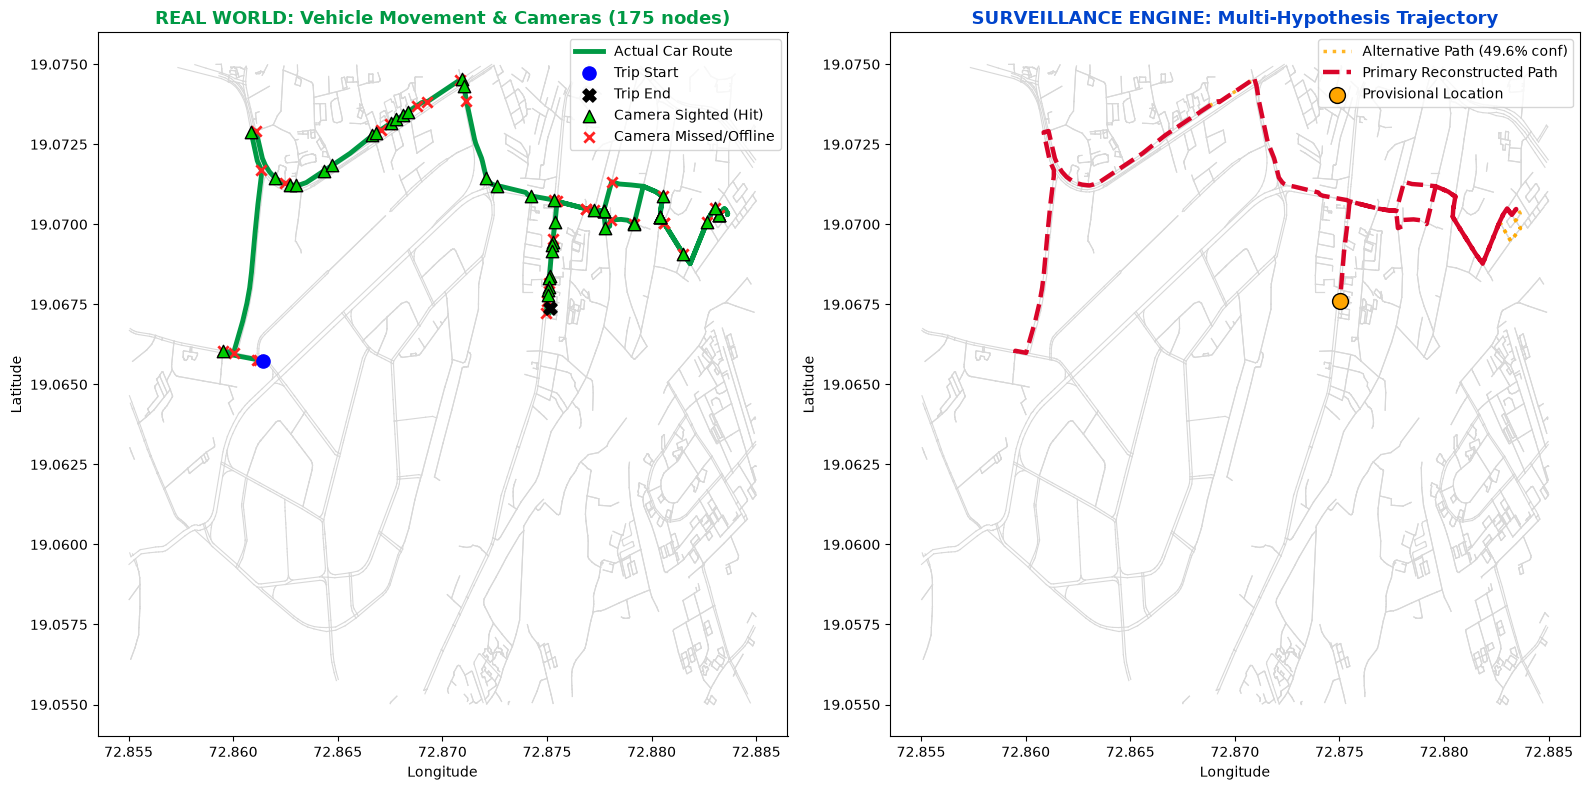

Trip Finished!
- Ground Truth Path Length      : 175 nodes
- Primary Inferred Route Length : 150 nodes
- Alternative Hypotheses Tracked: 3 uncertain corridors


In [6]:
import math
import heapq
import random
from datetime import datetime, timedelta
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# --- 1. SPATIAL & ROAD HELPERS ---

def calculate_haversine(lat1, lon1, lat2, lon2):
    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)
    a = math.sin(dlat/2)**2 + math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) * math.sin(dlon/2)**2
    return 6371000.0 * 2.0 * math.atan2(math.sqrt(a), math.sqrt(1.0 - a))

def get_road_specs(data):
    edge_len = data.get('length_m', 50.0)
    hw_type = data.get('highway_type', 'tertiary')
    
    speed_map = {
        'motorway': 70.0 / 3.6, 'trunk': 60.0 / 3.6, 'primary': 50.0 / 3.6,
        'secondary': 40.0 / 3.6, 'tertiary': 32.0 / 3.6, 'residential': 20.0 / 3.6,
        'unclassified': 22.0 / 3.6, 'service': 15.0 / 3.6
    }
    speed_mps = speed_map.get(hw_type, 28.0 / 3.6)

    hierarchy_weights = {
        'motorway': 0.65, 'trunk': 0.70, 'primary': 0.80,
        'secondary': 0.95, 'tertiary': 1.10, 'residential': 1.50, 'service': 2.00
    }
    h_weight = hierarchy_weights.get(hw_type, 1.15)
    return edge_len, speed_mps, h_weight

# --- 2. FAST MULTI-HYPOTHESIS GAP RESOLVER ---

def resolve_edge_gap_probabilistic(G, exit_node, entry_node, dt_seconds):
    if exit_node == entry_node:
        return [(100.0, [exit_node])]

    if dt_seconds <= 0:
        return [(100.0, [exit_node, entry_node])]

    target_lat = G.nodes[entry_node]['lat']
    target_lon = G.nodes[entry_node]['lon']

    # Priority Queue stores: (f_score, g_cost, raw_dist, time_sec, curr_node, path, prev_node, signals)
    pq = []
    for _, next_node, data in G.out_edges(exit_node, data=True):
        edge_len, speed_mps, h_weight = get_road_specs(data)
        travel_time = edge_len / speed_mps
        g_init = edge_len * h_weight
        h = calculate_haversine(G.nodes[next_node]['lat'], G.nodes[next_node]['lon'], target_lat, target_lon)
        heapq.heappush(pq, (g_init + h * 0.8, g_init, edge_len, travel_time, next_node, [exit_node, next_node], exit_node, 0))

    raw_candidates = []
    best_cost_to_node = {}
    max_evaluations = 5
    expansions = 0
    max_expansions = 1500  # Safety circuit-breaker to guarantee instant execution

    while pq and len(raw_candidates) < max_evaluations and expansions < max_expansions:
        expansions += 1
        f_score, g_cost, dist_so_far, time_so_far, curr_node, path, prev_node, signals = heapq.heappop(pq)

        if curr_node == entry_node:
            idle_sec = max(0.0, dt_seconds - time_so_far)
            max_idle_allowed = max(30.0, signals * 70.0)

            if time_so_far <= dt_seconds * 1.30:
                time_penalty = min(120.0, (idle_sec / max(1.0, max_idle_allowed)) * 50.0)
            else:
                time_penalty = 300.0

            raw_candidates.append((g_cost + time_penalty, path))
            continue

        # Prevent state explosion on bidirectional roads: tight pruning
        if curr_node in best_cost_to_node and best_cost_to_node[curr_node] <= g_cost:
            continue
        best_cost_to_node[curr_node] = g_cost

        is_signal = G.degree(curr_node) >= 3

        for _, next_node, data in G.out_edges(curr_node, data=True):
            # Eliminate immediate turnaround on the exact same two-way street segment
            if next_node == prev_node:
                continue

            # Prevent loops within current candidate
            if next_node in path:
                continue

            edge_len, speed_mps, h_weight = get_road_specs(data)
            step_cost = edge_len * h_weight
            new_g = g_cost + step_cost
            new_dist = dist_so_far + edge_len
            new_time = time_so_far + (edge_len / speed_mps)
            new_signals = signals + (1 if is_signal else 0)

            h = calculate_haversine(G.nodes[next_node]['lat'], G.nodes[next_node]['lon'], target_lat, target_lon)
            heapq.heappush(pq, (new_g + h * 0.8, new_g, new_dist, new_time, next_node, path + [next_node], curr_node, new_signals))

    if not raw_candidates:
        try:
            sp = nx.shortest_path(G, source=exit_node, target=entry_node, weight='length_m')
            return [(100.0, sp)]
        except:
            return [(100.0, [exit_node, entry_node])]

    # Convert to probability scores
    unique_candidates = {}
    for cost, path in raw_candidates:
        p_tuple = tuple(path)
        if p_tuple not in unique_candidates or unique_candidates[p_tuple] > cost:
            unique_candidates[p_tuple] = cost

    sorted_paths = sorted(unique_candidates.items(), key=lambda x: x[1])[:3]
    min_cost = sorted_paths[0][1]
    temp = 100.0
    exp_weights = [math.exp(-(cost - min_cost) / temp) for _, cost in sorted_paths]
    sum_exp = sum(exp_weights)

    prob_results = []
    for i, (path_tuple, _) in enumerate(sorted_paths):
        prob_pct = round((exp_weights[i] / sum_exp) * 100.0, 1)
        prob_results.append((prob_pct, list(path_tuple)))

    return prob_results

# --- 3. BUILD BI-DIRECTIONAL CAMERA LOOKUP ---

def build_bidirectional_camera_lookup(G, base_cam_lookup):
    bidirectional_lookup = {}
    for (u, v), cam in base_cam_lookup.items():
        bidirectional_lookup[(u, v)] = cam
        if G.has_edge(v, u):
            bidirectional_lookup[(v, u)] = cam
    return bidirectional_lookup

# --- 4. ROUTE SIMULATOR ---

def generate_highly_random_path(G, min_distance_m=1200):
    nodes = list(G.nodes())
    for _ in range(80):
        o = random.choice(nodes)
        d = random.choice(nodes)
        if o == d:
            continue
        try:
            if nx.shortest_path_length(G, o, d, weight='length_m') >= min_distance_m:
                mid1 = random.choice(nodes)
                mid2 = random.choice(nodes)
                waypoints = [o, mid1, mid2, d]

                full_path = []
                for idx in range(len(waypoints) - 1):
                    w_from = waypoints[idx]
                    w_to = waypoints[idx + 1]
                    def noisy_weight(u, v, data):
                        return data.get('length_m', 50.0) * random.uniform(0.7, 1.8)

                    leg = nx.shortest_path(G, w_from, w_to, weight=noisy_weight)
                    full_path.extend(leg if not full_path else leg[1:])

                if len(full_path) >= 25:
                    return o, d, full_path
        except:
            continue

    for _ in range(50):
        o, d = random.choice(nodes), random.choice(nodes)
        if o != d and nx.has_path(G, o, d):
            return o, d, nx.shortest_path(G, o, d, weight='length_m')
    raise ValueError("Path not found.")

# --- 5. STREAMING SIMULATION ---

def run_probabilistic_simulation(G, base_cam_lookup, min_distance_m=1200, camera_dropout=0.50):
    cam_lookup = build_bidirectional_camera_lookup(G, base_cam_lookup)
    origin, destination, valid_path = generate_highly_random_path(G, min_distance_m=min_distance_m)

    primary_reconstructed_route = []
    alternative_hypotheses = []
    active_cameras = []
    missed_cameras = []
    last_camera_hit = None
    curr_time = datetime(2026, 10, 30, 17, 30, 0)
    current_speed_kmh = 38.0

    road_lines = []
    for u, v in G.edges():
        road_lines.append(([G.nodes[u]['lon'], G.nodes[v]['lon']], [G.nodes[u]['lat'], G.nodes[v]['lat']]))

    for step in range(len(valid_path) - 1):
        u = valid_path[step]
        v = valid_path[step+1]
        edge_data = G.get_edge_data(u, v)

        road_len = edge_data.get('length_m', 60.0)
        current_speed_kmh = max(14.0, min(65.0, current_speed_kmh + random.uniform(-6.0, 6.0)))
        transit_sec = road_len / (current_speed_kmh / 3.6)
        curr_time += timedelta(seconds=transit_sec)

        if G.degree(v) >= 3 and random.random() < 0.22:
            curr_time += timedelta(seconds=random.uniform(20.0, 60.0))
            current_speed_kmh = 16.0

        cam = cam_lookup.get((u, v))
        if cam is not None:
            cam_pt = (cam['lon'], cam['lat'])
            if random.random() < camera_dropout:
                missed_cameras.append(cam_pt)
            else:
                active_cameras.append(cam_pt)
                current_hit = {
                    "edge_from": u,
                    "edge_to": v,
                    "timestamp": curr_time,
                    "speed_kmh": round(current_speed_kmh + random.gauss(0.0, 3.0), 1),
                    "camera_id": cam['camera_id']
                }

                if last_camera_hit is None:
                    primary_reconstructed_route.extend([u, v])
                else:
                    dt = (current_hit["timestamp"] - last_camera_hit["timestamp"]).total_seconds()
                    candidates = resolve_edge_gap_probabilistic(G, last_camera_hit["edge_to"], current_hit["edge_from"], dt)

                    best_prob, best_leg = candidates[0]
                    for n in best_leg:
                        if not primary_reconstructed_route or primary_reconstructed_route[-1] != n:
                            primary_reconstructed_route.append(n)
                    if primary_reconstructed_route[-1] != v:
                        primary_reconstructed_route.append(v)

                    if len(candidates) > 1 and candidates[0][0] < 80.0:
                        for p_val, alt_leg in candidates[1:]:
                            alternative_hypotheses.append((p_val, alt_leg))

                last_camera_hit = current_hit

    # --- SIDE-BY-SIDE RENDER ---
    clear_output(wait=True)
    fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(16, 8))

    for rx, ry in road_lines:
        ax_left.plot(rx, ry, color='#d8d8d8', linewidth=0.8, zorder=1)
        ax_right.plot(rx, ry, color='#d8d8d8', linewidth=0.8, zorder=1)

    # 1. LEFT PANEL: Ground Truth
    gt_lons = [G.nodes[n]['lon'] for n in valid_path]
    gt_lats = [G.nodes[n]['lat'] for n in valid_path]
    ax_left.plot(gt_lons, gt_lats, color='#009944', linewidth=3.5, label='Actual Car Route', zorder=3)
    ax_left.scatter(gt_lons[0], gt_lats[0], color='blue', s=90, marker='o', label='Trip Start', zorder=5)
    ax_left.scatter(gt_lons[-1], gt_lats[-1], color='black', s=90, marker='X', label='Trip End', zorder=5)

    if active_cameras:
        c_lons, c_lats = zip(*active_cameras)
        ax_left.scatter(c_lons, c_lats, color='#00cc00', edgecolor='black', s=80, marker='^', label='Camera Sighted (Hit)', zorder=6)

    if missed_cameras:
        m_lons, m_lats = zip(*missed_cameras)
        ax_left.scatter(m_lons, m_lats, color='#ff2222', s=55, marker='x', linewidths=2.0, label='Camera Missed/Offline', zorder=4)

    ax_left.set_title(f"REAL WORLD: Vehicle Movement & Cameras ({len(valid_path)} nodes)", fontsize=13, fontweight='bold', color='#009944')
    ax_left.legend(loc='upper right')
    ax_left.set_xlabel("Longitude")
    ax_left.set_ylabel("Latitude")

    # 2. RIGHT PANEL: Multi-Hypothesis Surveillance
    alt_plotted = False
    for prob, alt_path in alternative_hypotheses:
        if len(alt_path) > 1:
            a_lons = [G.nodes[n]['lon'] for n in alt_path]
            a_lats = [G.nodes[n]['lat'] for n in alt_path]
            lbl = f"Alternative Path ({prob}% conf)" if not alt_plotted else ""
            ax_right.plot(a_lons, a_lats, color='#ffaa00', linestyle=':', linewidth=2.5, alpha=0.85, label=lbl, zorder=2)
            alt_plotted = True

    if primary_reconstructed_route:
        calc_lons = [G.nodes[n]['lon'] for n in primary_reconstructed_route]
        calc_lats = [G.nodes[n]['lat'] for n in primary_reconstructed_route]
        ax_right.plot(calc_lons, calc_lats, color='#d90429', linestyle='--', linewidth=3.2, label='Primary Reconstructed Path', zorder=4)
        last_n = primary_reconstructed_route[-1]
        ax_right.scatter(G.nodes[last_n]['lon'], G.nodes[last_n]['lat'], color='orange', s=130, edgecolor='black', label='Provisional Location', zorder=6)

    ax_right.set_title("SURVEILLANCE ENGINE: Multi-Hypothesis Trajectory", fontsize=13, fontweight='bold', color='#0044cc')
    ax_right.legend(loc='upper right')
    ax_right.set_xlabel("Longitude")
    ax_right.set_ylabel("Latitude")

    plt.tight_layout()
    display(fig)
    plt.close()

    print(f"Trip Finished!")
    print(f"- Ground Truth Path Length      : {len(valid_path)} nodes")
    print(f"- Primary Inferred Route Length : {len(primary_reconstructed_route)} nodes")
    print(f"- Alternative Hypotheses Tracked: {len(alternative_hypotheses)} uncertain corridors")

# Execute
run_probabilistic_simulation(G, cam_lookup, min_distance_m=1200, camera_dropout=0.50)

Optimal Camera Placement

In [17]:
import random
import networkx as nx
import matplotlib.pyplot as plt

# =====================================================================
# 1. GENERATE BALANCED OD TRANSIT FLOWS
# =====================================================================
def generate_balanced_od_trips(G, num_trips=2500, min_nodes_per_trip=10):
    print(f"Generating {num_trips} balanced synthetic traffic corridors across the road network...")
    nodes = list(G.nodes())
    trips = []

    def route_weight(u, v, data):
        hw = data.get('highway_type', 'residential')
        length = data.get('length_m', 50.0)
        hierarchy_penalties = {
            'motorway': 0.7, 'trunk': 0.75, 'primary': 0.85,
            'secondary': 1.0, 'tertiary': 1.15, 'residential': 1.6
        }
        return length * hierarchy_penalties.get(hw, 1.2)

    attempts = 0
    max_attempts = num_trips * 4

    while len(trips) < num_trips and attempts < max_attempts:
        attempts += 1
        src = random.choice(nodes)
        dst = random.choice(nodes)
        if src == dst:
            continue

        try:
            node_path = nx.shortest_path(G, src, dst, weight=route_weight)
            if len(node_path) >= min_nodes_per_trip:
                edge_path = [(node_path[i], node_path[i+1]) for i in range(len(node_path) - 1)]
                trips.append(edge_path)
        except (nx.NetworkXNoPath, nx.NodeNotFound):
            continue

    print(f"Generated {len(trips)} valid routes spanning the network.")
    return trips


# =====================================================================
# 2. DUAL-MODE OPTIMAL CAMERA PLACEMENT SOLVER
# =====================================================================
def solve_camera_placement_dual_mode(
    G, 
    trips, 
    budget_k=None, 
    target_coverage_pct=None, 
    require_multi_hit=False
):
    if budget_k is None and target_coverage_pct is None:
        raise ValueError("Must provide either budget_k or target_coverage_pct!")

    total_trips = len(trips)
    target_hits_needed = 2 if require_multi_hit else 1

    print("=" * 65)
    if target_coverage_pct is not None:
        mode_str = f"MINIMAL CAMERAS FOR {target_coverage_pct * 100:.1f}% COVERAGE"
    else:
        mode_str = f"MAX COVERAGE FOR FIXED BUDGET K = {budget_k}"
    print(f"OPTIMIZATION MODE: {mode_str}")
    print(f"Criteria: {'Trajectory Recoverability (>=2 hits)' if require_multi_hit else 'Flow Interception (>=1 hit)'}")
    print("=" * 65)

    edge_to_trips = {}
    for trip_id, edge_path in enumerate(trips):
        for edge in edge_path:
            u, v = edge
            edge_key = (u, v) if (u, v) in G.edges else (v, u)
            if edge_key not in edge_to_trips:
                edge_to_trips[edge_key] = set()
            edge_to_trips[edge_key].add(trip_id)

    trip_hit_counts = [0] * total_trips
    covered_trip_ids = set()
    selected_edges = []

    step = 0
    while True:
        step += 1

        if budget_k is not None and len(selected_edges) >= budget_k:
            break

        if target_coverage_pct is not None:
            current_pct = len(covered_trip_ids) / total_trips
            if current_pct >= target_coverage_pct:
                break

        best_edge = None
        best_gain = 0
        trips_affected_by_best = []

        for edge, passing_trips in edge_to_trips.items():
            gain = 0
            affected = []
            for t_id in passing_trips:
                if trip_hit_counts[t_id] < target_hits_needed:
                    gain += 1
                    affected.append(t_id)

            if gain > best_gain:
                best_gain = gain
                best_edge = edge
                trips_affected_by_best = affected

        if not best_edge or best_gain == 0:
            print("No more edges can add coverage to remaining trips.")
            break

        selected_edges.append((best_edge, len(edge_to_trips[best_edge]), best_gain))
        for t_id in trips_affected_by_best:
            trip_hit_counts[t_id] += 1
            if trip_hit_counts[t_id] >= target_hits_needed:
                covered_trip_ids.add(t_id)

        del edge_to_trips[best_edge]

    final_coverage_pct = (len(covered_trip_ids) / total_trips) * 100.0

    print("=" * 65)
    print(f"RESULTS:")
    print(f"- Total Trips Tested           : {total_trips}")
    print(f"- Minimum Cameras Placed       : {len(selected_edges)}")
    print(f"- Target Coverage Achieved     : {len(covered_trip_ids)} / {total_trips} ({final_coverage_pct:.2f}%)")
    print("=" * 65)

    placed_cameras = []
    for idx, ((u, v), total_traffic, marginal_gain) in enumerate(selected_edges):
        u_data = G.nodes[u]
        v_data = G.nodes[v]
        edge_data = G.get_edge_data(u, v) or G.get_edge_data(v, u) or {}

        placed_cameras.append({
            "camera_id": f"CAM_OPT_{idx+1:04d}",
            "edge_from": u,
            "edge_to": v,
            "lat": (u_data['lat'] + v_data['lat']) / 2.0,
            "lon": (u_data['lon'] + v_data['lon']) / 2.0,
            "highway_type": edge_data.get('highway_type', 'road'),
            "total_intercepted_trips": total_traffic,
            "marginal_new_trips": marginal_gain
        })

    return placed_cameras


# =====================================================================
# 3. COMPREHENSIVE COVERAGE & BLIND GAP EVALUATION
# =====================================================================
def evaluate_camera_network_coverage(G, trips, optimal_cameras):
    monitored_edges = set()
    for cam in optimal_cameras:
        u, v = cam['edge_from'], cam['edge_to']
        monitored_edges.add((u, v))
        if G.has_edge(v, u):
            monitored_edges.add((v, u))

    total_trips = len(trips)
    zero_hits = 0
    single_hit = 0
    multi_hits = 0
    blind_gap_lengths_m = []

    for edge_path in trips:
        hit_indices = []
        for idx, edge in enumerate(edge_path):
            if edge in monitored_edges or (edge[1], edge[0]) in monitored_edges:
                hit_indices.append(idx)

        hits_count = len(hit_indices)
        if hits_count == 0:
            zero_hits += 1
        elif hits_count == 1:
            single_hit += 1
        else:
            multi_hits += 1
            for i in range(len(hit_indices) - 1):
                start_step = hit_indices[i]
                end_step = hit_indices[i + 1]
                gap_dist = sum(
                    G.get_edge_data(edge_path[s][0], edge_path[s][1], {}).get('length_m', 50.0)
                    for s in range(start_step, end_step)
                )
                blind_gap_lengths_m.append(gap_dist)

    avg_gap_m = (sum(blind_gap_lengths_m) / len(blind_gap_lengths_m)) if blind_gap_lengths_m else 0.0

    print("=" * 65)
    print("      CAMERAS PLACEMENT COVERAGE & RECOVERABILITY REPORT      ")
    print("=" * 65)
    print(f"Total Cameras Evaluated           : {len(optimal_cameras)}")
    print(f"Total Trips Evaluated             : {total_trips}")
    print("-" * 65)
    print(f"1+ Hit Interception Rate          : {((total_trips - zero_hits) / total_trips) * 100:.2f}% ({(total_trips - zero_hits)} trips)")
    print(f"2+ Hits (Trajectory Recoverable)  : {(multi_hits / total_trips) * 100:.2f}% ({multi_hits} trips)")
    print(f"1-Hit Only (Spotted, Not Tracked) : {(single_hit / total_trips) * 100:.2f}% ({single_hit} trips)")
    print(f"Zero Sightings (Complete Miss)    : {(zero_hits / total_trips) * 100:.2f}% ({zero_hits} trips)")
    print("-" * 65)
    print(f"Average Unmonitored Blind Gap     : {avg_gap_m:.1f} meters")
    print("=" * 65)

Generating 2500 balanced synthetic traffic corridors across the road network...
Generated 2500 valid routes spanning the network.
OPTIMIZATION MODE: MINIMAL CAMERAS FOR 100.0% COVERAGE
Criteria: Flow Interception (>=1 hit)
RESULTS:
- Total Trips Tested           : 2500
- Minimum Cameras Placed       : 130
- Target Coverage Achieved     : 2500 / 2500 (100.00%)

Answer: To achieve 100% interception across these 2500 corridors, you need 130 cameras.

Top 5 Strategic Choke Points Found by Algorithm:
- CAM_OPT_0001 (road): Caught 503 total trips (Added +503 unique corridors)
- CAM_OPT_0002 (road): Caught 470 total trips (Added +464 unique corridors)
- CAM_OPT_0003 (road): Caught 313 total trips (Added +231 unique corridors)
- CAM_OPT_0004 (road): Caught 374 total trips (Added +136 unique corridors)
- CAM_OPT_0005 (road): Caught 218 total trips (Added +115 unique corridors)


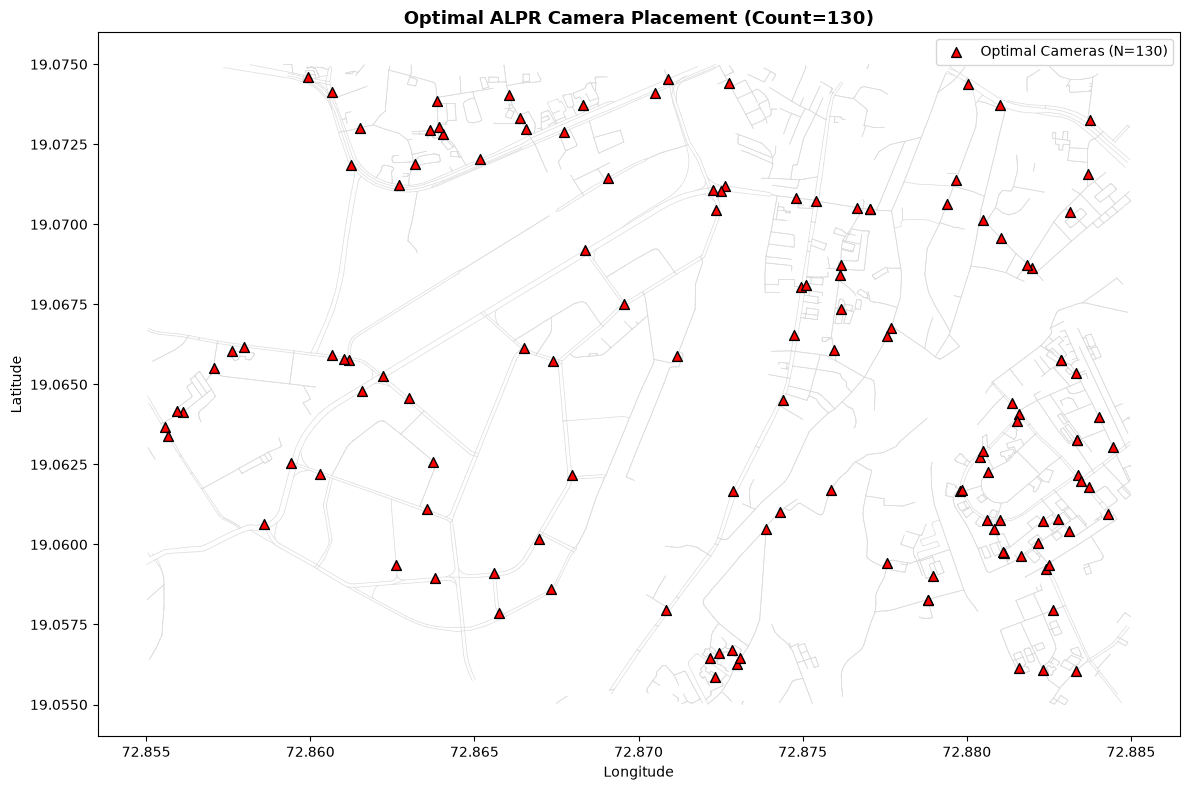

      CAMERAS PLACEMENT COVERAGE & RECOVERABILITY REPORT      
Total Cameras Evaluated           : 130
Total Trips Evaluated             : 2500
-----------------------------------------------------------------
1+ Hit Interception Rate          : 100.00% (2500 trips)
2+ Hits (Trajectory Recoverable)  : 89.92% (2248 trips)
1-Hit Only (Spotted, Not Tracked) : 10.08% (252 trips)
Zero Sightings (Complete Miss)    : 0.00% (0 trips)
-----------------------------------------------------------------
Average Unmonitored Blind Gap     : 310.0 meters


In [18]:
# Step A: Sample 2,500 balanced corridors
trips_pool = generate_balanced_od_trips(G, num_trips=2500)

# Step B: Solve for 100% interception coverage
optimal_cams = solve_camera_placement_dual_mode(
    G, 
    trips_pool, 
    target_coverage_pct=1.0  # Or set budget_k=150 to solve for a fixed budget
)

print(f"\nAnswer: To achieve 100% interception across these {len(trips_pool)} corridors, you need {len(optimal_cams)} cameras.")

# Step C: Top 5 Strategic Choke Points
print("\nTop 5 Strategic Choke Points Found by Algorithm:")
for c in optimal_cams[:5]:
    print(f"- {c['camera_id']} ({c['highway_type']}): Caught {c['total_intercepted_trips']} total trips (Added +{c['marginal_new_trips']} unique corridors)")

# Step D: Geographic Map of Placed Cameras
plt.figure(figsize=(12, 8))
for u, v in G.edges():
    plt.plot(
        [G.nodes[u]['lon'], G.nodes[v]['lon']],
        [G.nodes[u]['lat'], G.nodes[v]['lat']],
        color='#dcdcdc', linewidth=0.5, zorder=1
    )

cam_lons = [c['lon'] for c in optimal_cams]
cam_lats = [c['lat'] for c in optimal_cams]
plt.scatter(
    cam_lons, cam_lats, 
    c='red', edgecolor='black', s=50, marker='^', 
    label=f'Optimal Cameras (N={len(optimal_cams)})', zorder=3
)
plt.title(f"Optimal ALPR Camera Placement (Count={len(optimal_cams)})", fontsize=13, fontweight='bold')
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# Step E: Evaluate against full recoverability and blind gap distance
evaluate_camera_network_coverage(G, trips_pool, optimal_cams)